## A Mathematical Introduction to Machine Learning (5MA206), HT26
# Computer lab 1, part A: linear regression

**Instructions**
* Work through the notebook from top to bottom. Complete the code cells marked `# EDIT`, and answer the numbered
  questions **Q1, Q2, …** in the text cells below them.
* You may work in pairs. Write both names below.
* Before you submit: restart the kernel and run all cells (*Kernel* menu), and check that the notebook runs from start to
  finish without errors.
* Lab 1 consists of part A (this notebook) and part B (PCA). Submit both notebooks together as one zip file on Canvas.

**Names:** Michael Sederlund Evans

In this lab we fit models of the form
$$
f(x)=\sum_{k=0}^{K-1}\theta_k\,\phi_k(x)=\boldsymbol\phi(x)^\top\boldsymbol\theta
$$
to data $\{(x_n,y_n)\}_{n=1}^N$. We choose the **features** $\phi_k(x)$ ourselves; they may be non-linear functions of $x$,
for example $\phi_k(x)=x^k$. The **parameters** $\theta_k$ are learned from the data. The model is linear in the parameters,
hence the name *linear regression* (MML Chapter 9, Lectures 3–4).

You will
* compute the maximum likelihood estimate of $\boldsymbol\theta$ (Lecture 3),
* see underfitting and overfitting, and compare the training error with the test error (Lectures 2 and 4),
* choose the model by cross-validation (Lecture 2),
* use ridge regression, which is MAP estimation with a Gaussian prior (Lecture 4),
* estimate the noise variance (Lecture 3).

Python counts from 0, so the code uses $n=0,\dots,N-1$ where the lectures use $n=1,\dots,N$.

**Packages.** The next cell installs the packages this lab needs, if they are missing (this needs an internet
connection). If they are already installed, as in Google Colab or a Miniforge environment set up as on the lab slides,
it only prints `Requirement already satisfied`. If it installed something new and an import below fails, restart the
kernel (*Kernel* menu) and run the notebook again.

In [2]:
%pip install numpy matplotlib

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. The data

We generate data from a known function plus Gaussian noise, $y=f_{\mathrm{true}}(x)+\varepsilon$ with
$\varepsilon\sim\mathcal N(0,\sigma^2)$. In a real problem you know neither $f_{\mathrm{true}}$ nor $\sigma$; here we know
them, so that we can check what the methods do.

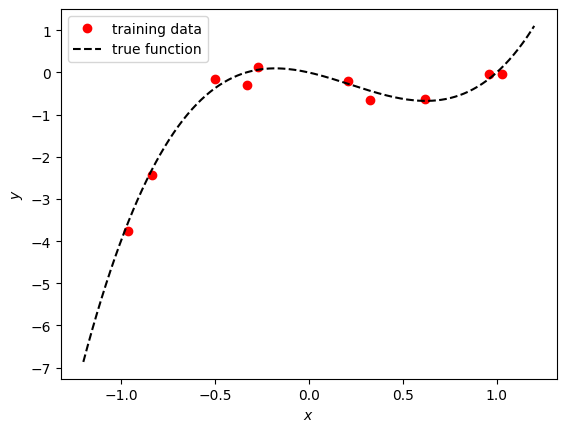

In [2]:
rng = np.random.default_rng(33)   # fixed seed: everybody gets the same data

def f_true(x):
    # the function behind the data (unknown in a real problem)
    return -1.0*x - 2.0*x**2 + 3.0*x**3

sigma = 0.2   # standard deviation of the noise (also unknown in a real problem)

def sample(x):
    # noisy observations y = f_true(x) + noise at the points x (an N x 1 array)
    return f_true(x) + sigma*rng.normal(size=x.shape)

N = 10
x_train = np.linspace(-1, 1, N).reshape(-1, 1) + 0.1*rng.normal(size=(N, 1))
y_train = sample(x_train)

xx = np.linspace(-1.2, 1.2, 200).reshape(-1, 1)   # a fine grid, only used for plotting

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

## 2. A straight line

The function `model` turns features and parameters into a function $x\mapsto\boldsymbol\phi(x)^\top\boldsymbol\theta$.
The features of a straight line are $\boldsymbol\phi(x)=(1,x)$, so $f(x)=\theta_0+\theta_1x$. For $N$ inputs,
`linear_features` returns the $N\times2$ feature matrix $\boldsymbol\Phi$, whose rows are $\boldsymbol\phi(x_n)^\top$.

In [3]:
def model(features, theta):
    # the model x -> phi(x)^T theta, where features(x) returns the N x K feature matrix Phi
    return lambda x: features(x) @ theta

def linear_features(x):
    # features phi(x) = (1, x): returns the N x 2 matrix Phi
    return np.hstack([np.ones_like(x), x])

Try to find a good line by hand: change `theta_guess` and rerun the cell.

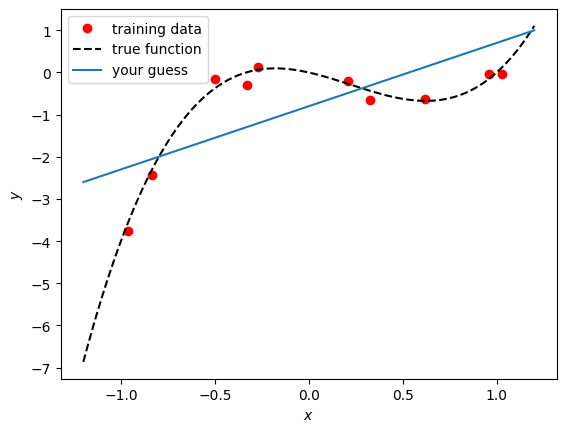

In [20]:
theta_guess = np.array([[-0.8], [1.5]])   # EDIT: try to find better values
f_guess = model(linear_features, theta_guess)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label='your guess')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

### Measuring the error
A systematic way to judge a model is the **root-mean-square error**
$$
\mathrm{RMSE}=\sqrt{\frac1N\sum_{n=1}^N\bigl(y_n-f(x_n)\bigr)^2}.
$$
Its square is the empirical risk with the squared loss (Lecture 1). Complete the function.

In [21]:
def rmse(y, y_pred):
    # root-mean-square error between two N x 1 arrays
    return np.sqrt(np.mean((y - y_pred)**2))

print('training RMSE of your guess:', rmse(y_train, f_guess(x_train)))

training RMSE of your guess: 0.9472525504708885


### Maximum likelihood
With Gaussian noise, the maximum likelihood estimate $\boldsymbol\theta_{\mathrm{ML}}$ solves the **normal equations**
(Lecture 3)
$$
\boldsymbol\Phi^\top\boldsymbol\Phi\,\boldsymbol\theta=\boldsymbol\Phi^\top\boldsymbol y .
$$
Complete `fit_ml`. Use `np.linalg.solve` rather than computing the inverse $(\boldsymbol\Phi^\top\boldsymbol\Phi)^{-1}$:
solving the system is cheaper and more accurate.

theta_ML = [-0.83807334  1.15566739]


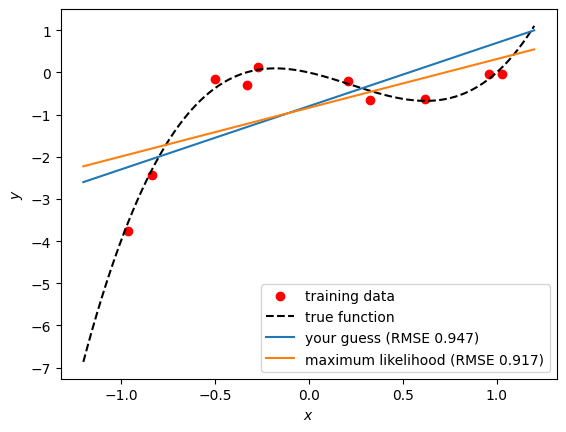

In [25]:
def fit_ml(Phi, y):
    # maximum likelihood estimate: the solution of Phi^T Phi theta = Phi^T y
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ y)

Phi_line = linear_features(x_train)
theta_line = fit_ml(Phi_line, y_train)
f_line = model(linear_features, theta_line)
print('theta_ML =', theta_line.ravel())

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label=f'your guess (RMSE {rmse(y_train, f_guess(x_train)):.3f})')
plt.plot(xx, f_line(xx), label=f'maximum likelihood (RMSE {rmse(y_train, f_line(x_train)):.3f})')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

**Q1.** Does the fitted line describe the data well? Does it describe the true function well?

**Q2.** Why does $\boldsymbol\theta_{\mathrm{ML}}$ give a smaller training RMSE than any other line, including your guess?
(Hint: Lecture 3. What does maximising the likelihood with Gaussian noise amount to?)

**Q1**
 I would not say that the fitted line describes the data well for either one of them. 
For the data, the line goes through the middle of the points and gets the overall upward trend right. But the points bend as they rise steeply on the left, flatten and dip in the middle, then rise again on the right. So a straight line misses a lot. The RMSE is large compared with the noise level σ = 0.2, which tells you the error comes mainly from the model being too simple.

When looking at the true function it is even worse. As this is a cubic function with an S shape. So the line only catches it average tilt and is far off at the edges, especially near x=-1.

**Q2** 
With Gaussian noise, the likelihood is largest when the squared errors are smallest. So maximum likelihood is the same as least squares.  $\boldsymbol\theta_{\mathrm{ML}}$ is the line with the smallest possible $\sum_{n=1}^N \bigl(y_n - f(x_n)\bigr)^2$ on the training data. RMSE is jut the sum divided by N with a square root taken, which doesn't change which line wins. So no other line can get a lower training RMSE.

The next cell computes the residual vector $\boldsymbol r=\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta_{\mathrm{ML}}$ and
$\boldsymbol\Phi^\top\boldsymbol r$.

In [26]:
r = y_train - Phi_line @ theta_line
print('Phi^T r =', (Phi_line.T @ r).ravel())

Phi^T r = [1.77635684e-15 2.98003290e-16]


**Q3.** $\boldsymbol\Phi^\top\boldsymbol r$ is zero up to rounding errors. Which equation says this? What does it mean
geometrically? (Lecture 4)

The normal equations. $\boldsymbol\Phi^\top\boldsymbol\Phi\,\boldsymbol\theta = \boldsymbol\Phi^\top\boldsymbol y$ can be rewritten as $\boldsymbol\Phi^\top(\boldsymbol y - \boldsymbol\Phi\boldsymbol\theta) = \boldsymbol 0$, which is $\boldsymbol\Phi^\top\boldsymbol r = \boldsymbol 0$.
The residual vector $\boldsymbol r$ is orthogonal to the columns of $\boldsymbol\Phi$. Think of a shadow: the closest point on a floor to a ball in the air is straight below it, and the line from the ball to its shadow is perpendicular to the floor. Here the "floor" is everything a straight line can predict, $\boldsymbol\Phi\boldsymbol\theta$ is the shadow of $\boldsymbol y$, and $\boldsymbol r$ is the perpendicular line from $\boldsymbol y$ down to it.

## 3. Polynomials of higher degree

A polynomial of degree $M$ has the features $\boldsymbol\phi(x)=(1,x,x^2,\dots,x^M)$, so $K=M+1$. Complete
`poly_features`, then try a few degrees $M$ in the cell after it (MML 9.2.2, Lecture 4).

In [27]:
def poly_features(x, M):
    # features phi(x) = (1, x, ..., x^M): returns the N x (M+1) matrix Phi
    Phi = np.hstack([x**m for m in range(M+1)])
    return Phi

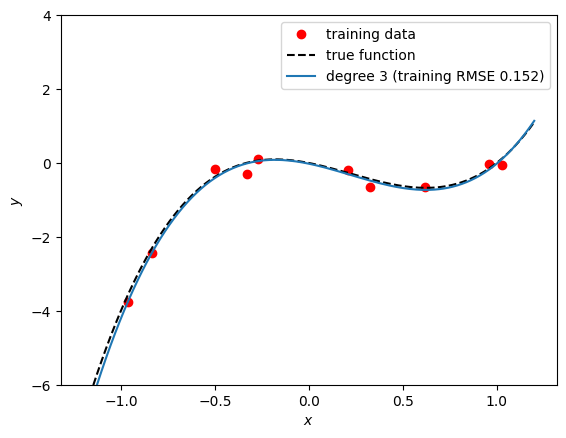

In [42]:
M = 3  # try different degrees
features = lambda x: poly_features(x, M)
theta = fit_ml(features(x_train), y_train)
f_M = model(features, theta)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_M(xx), label=f'degree {M} (training RMSE {rmse(y_train, f_M(x_train)):.3f})')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

Complete the loop, which computes the training RMSE for $M=0,1,\dots,9$.

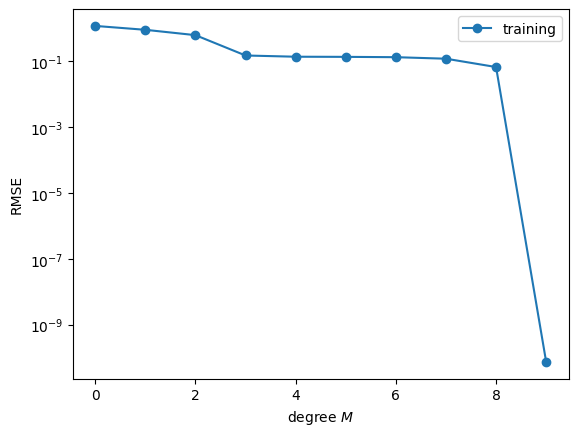

In [37]:
M_max = 9
train_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = fit_ml(features(x_train), y_train)
    train_rmse[M] = rmse(y_train, features(x_train) @ theta)

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

In [43]:
for M in [1, 3, 6, 9]:
    Phi = poly_features(x_train, M)
    print(f'M = {M}: rank of Phi = {np.linalg.matrix_rank(Phi)}, condition number of Phi^T Phi = {np.linalg.cond(Phi.T @ Phi):.1e}')

M = 1: rank of Phi = 2, condition number of Phi^T Phi = 2.2e+00
M = 3: rank of Phi = 4, condition number of Phi^T Phi = 5.4e+01
M = 6: rank of Phi = 7, condition number of Phi^T Phi = 1.8e+04
M = 9: rank of Phi = 10, condition number of Phi^T Phi = 1.0e+08


**Q4.** Which degree $M$ gives the smallest training RMSE, and why? For which $M$ is the model underfitting, and for which
is it overfitting? (Plot a few of the fits above.)

**Q5.** The condition number of $\boldsymbol\Phi^\top\boldsymbol\Phi$ grows quickly with $M$. Why does that cause
numerical problems? What would happen for $M\ge N=10$? (Hint: the rank of $\boldsymbol\Phi$, Lecture 3.)

**Q4.** $M = 9$ gives the smallest training RMSE (almost $0$). With $N = 10$ points and $K = M + 1 = 10$ parameters, the polynomial can pass exactly through every point. That doesn't make it a good model because it fits the noise and wiggles between the points.

* **Underfitting:** $M = 0, 1, 2$. The model is too simple to follow the shape of the data.
* **Good fit:** $M = 3$. It has the same shape as the true cubic function, and its training RMSE $\approx 0.15$ is close to the noise level $\sigma = 0.2$.
* **Overfitting:** large $M$, clearly $M = 8, 9$. The training error keeps falling, but only because the curve follows the noise.

**Q5.** To find $\boldsymbol\theta_{\mathrm{ML}}$ we solve $\boldsymbol\Phi^\top\boldsymbol\Phi\,\boldsymbol\theta = \boldsymbol\Phi^\top\boldsymbol y$. A large condition number means small rounding errors get blown up into large errors in $\boldsymbol\theta$. Roughly $\log_{10}(\text{cond})$ digits of accuracy are lost. For $M = 9$, $\text{cond} \approx 10^8$, so about 8 of the 16 digits are lost. The columns $x^k$ become very similar to each other on $[-1, 1]$, which makes the system close to singular.

For $M \ge N = 10$, $\boldsymbol\Phi$ is $N \times (M+1)$ with more columns than rows, so
$$
\operatorname{rank}(\boldsymbol\Phi) \le N < M + 1 .
$$
Then $\boldsymbol\Phi^\top\boldsymbol\Phi$ (size $(M+1)\times(M+1)$) is singular and cannot be inverted. The normal equations have infinitely many solutions (many polynomials pass exactly through all points), so $\boldsymbol\theta_{\mathrm{ML}}$ is not unique, and `np.linalg.solve` either fails or returns a meaningless result.

## 4. Training error and test error

Because we generated the data ourselves, we can draw a large **test set** from the same distribution. Its RMSE is close
to the root of the true risk (Lecture 2). In practice you only have your $N$ data points, and a test set may be used only
once, at the very end, to report the performance of the model you have chosen.

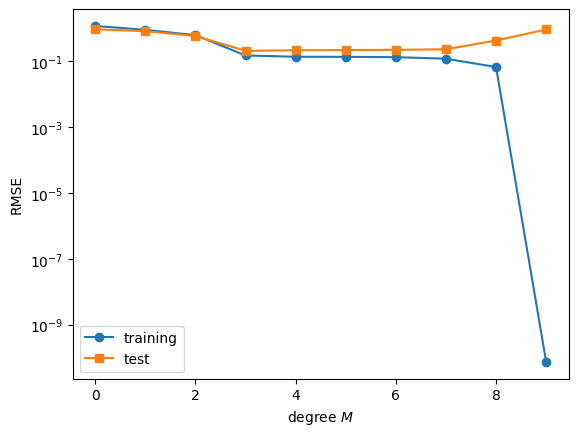

In [45]:
x_test = rng.uniform(-1, 1, size=(1000, 1))
y_test = sample(x_test)

test_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = fit_ml(features(x_train), y_train)
    test_rmse[M] = rmse(y_test, features(x_test) @ theta)

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q6.** Which degree has the smallest test RMSE? Compare with the true function. Describe overfitting in terms of the two
curves.

$M = 3$ has the smallest test RMSE. This matches the true function. The test RMSE can't go much below the noise level $\sigma = 0.2$, because the noise can't be predicted. So $M = 3$ is about as good as any model can be.

**Overfitting in terms of the two curves:**
* For $M = 0, 1, 2$ both curves are high and close together. The model is too simple (underfitting).
* For $M = 3$ to $7$ both curves are low and flat, near $\sigma = 0.2$.
* For $M = 8, 9$ the curves split apart: the training RMSE keeps falling (almost $0$ at $M = 9$), but the test RMSE rises again at $M = 9$. The model fits the noise in the training data, and that doesn't carry over to new data.

So overfitting is when the training error is small but the test error is much larger. A low training error alone does not mean a good model.

## 5. Choosing the degree by cross-validation

The test set must not be used to choose $M$: then it no longer measures the performance on new data (Lecture 2). Instead
we estimate the test error from the training data alone, with **leave-one-out cross-validation**: for each $n$, fit the
model to all training points except $(x_n,y_n)$, and compute the squared error of the prediction at $x_n$. The CV-RMSE is
the root of the average of these $N$ errors.

Complete `loocv_rmse`. The argument `fit` is the fitting method, for example `fit_ml`.

degree chosen by cross-validation: 3


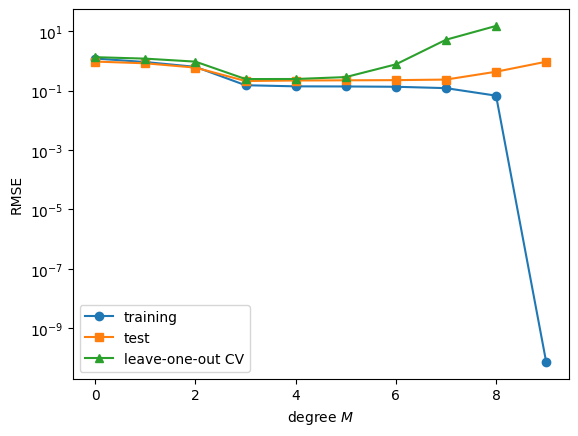

In [46]:
def loocv_rmse(x, y, features, fit):
    # leave-one-out cross-validation estimate of the RMSE
    N = x.shape[0]
    errors = np.zeros(N)
    for n in range(N):
        keep = np.arange(N) != n           # every point except number n
        theta = fit(features(x[keep]), y[keep])
        y_pred = features(x[n:n+1]) @ theta
        errors[n] = (y[n,0] - y_pred[0,0])**2
    return np.sqrt(np.mean(errors))

M_cv = 8
cv_rmse = np.array([loocv_rmse(x_train, y_train, lambda x: poly_features(x, M), fit_ml) for M in range(M_cv + 1)])
M_best = int(np.argmin(cv_rmse))
print('degree chosen by cross-validation:', M_best)

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.semilogy(range(M_cv + 1), cv_rmse, '^-', label='leave-one-out CV')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q7.** Which degree does cross-validation choose? Does it agree with the test error? Why does the cross-validation curve
stop at $M=8$, i.e. what would go wrong for $M=9$?

**Q7.** Cross-validation chooses $M = 3$, the same degree as the smallest test RMSE. The CV curve has the same shape as the test curve, high for small $M$ (underfitting), lowest around $M = 3$–$4$, and rising for large $M$ (overfitting). For large $M$ the CV error is even larger than the test error, because each fit uses only $9$ points instead of $10$, which makes overfitting worse.

The curve stops at $M = 8$ because in leave-one-out each fit uses only $N - 1 = 9$ points. For $M = 9$ the model has $K = M + 1 = 10$ parameters, so
$$
\operatorname{rank}(\boldsymbol\Phi) \le 9 < 10 ,
$$
and $\boldsymbol\Phi^\top\boldsymbol\Phi$ is singular (as in Q5). There are 10 unknowns but only 9 equations, so infinitely many polynomials pass exactly through the 9 points, and $\boldsymbol\theta_{\mathrm{ML}}$ is not unique.

## 6. Ridge regression

Instead of choosing a small degree, we can keep a flexible model and penalise large parameters. **Ridge regression**
minimises
$$
\|\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta\|^2+\lambda\|\boldsymbol\theta\|^2 ,
$$
and the minimiser is
$$
\boldsymbol\theta_{\mathrm{ridge}}=(\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I)^{-1}\boldsymbol\Phi^\top\boldsymbol y .
$$

**Q8.** Derive this formula: compute the gradient of the objective with respect to $\boldsymbol\theta$ and set it to zero.

$$
L(\boldsymbol\theta) = (\boldsymbol y - \boldsymbol\Phi\boldsymbol\theta)^\top(\boldsymbol y - \boldsymbol\Phi\boldsymbol\theta) + \lambda\boldsymbol\theta^\top\boldsymbol\theta
= \boldsymbol y^\top\boldsymbol y - 2\boldsymbol y^\top\boldsymbol\Phi\boldsymbol\theta + \boldsymbol\theta^\top\boldsymbol\Phi^\top\boldsymbol\Phi\boldsymbol\theta + \lambda\boldsymbol\theta^\top\boldsymbol\theta .
$$
Using $\nabla_{\boldsymbol\theta}(\boldsymbol b^\top\boldsymbol\theta) = \boldsymbol b$ and $\nabla_{\boldsymbol\theta}(\boldsymbol\theta^\top\boldsymbol A\boldsymbol\theta) = 2\boldsymbol A\boldsymbol\theta$ for symmetric $\boldsymbol A$, the gradient is
$$
\nabla_{\boldsymbol\theta} L = -2\boldsymbol\Phi^\top\boldsymbol y + 2\boldsymbol\Phi^\top\boldsymbol\Phi\boldsymbol\theta + 2\lambda\boldsymbol\theta .
$$
Setting it to zero gives
$$
(\boldsymbol\Phi^\top\boldsymbol\Phi + \lambda\boldsymbol I)\,\boldsymbol\theta = \boldsymbol\Phi^\top\boldsymbol y
\quad\Rightarrow\quad
\boldsymbol\theta_{\mathrm{ridge}} = (\boldsymbol\Phi^\top\boldsymbol\Phi + \lambda\boldsymbol I)^{-1}\boldsymbol\Phi^\top\boldsymbol y .
$$
This is a minimum because $L$ is convex: its Hessian $2(\boldsymbol\Phi^\top\boldsymbol\Phi + \lambda\boldsymbol I)$ is positive definite for $\lambda > 0$.

Complete `fit_ridge` (again with `np.linalg.solve`).

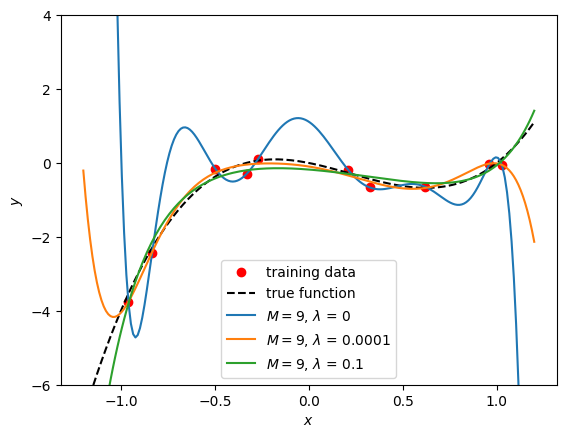

In [47]:
def fit_ridge(Phi, y, lam):
    # ridge regression: minimise ||y - Phi theta||^2 + lam ||theta||^2
    K = Phi.shape[1]
    return np.linalg.solve(Phi.T @ Phi + lam*np.eye(K), Phi.T @ y)

M = 9
features = lambda x: poly_features(x, M)
plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
for lam in [0, 1e-4, 1e-1]:
    theta = fit_ridge(features(x_train), y_train, lam)
    plt.plot(xx, model(features, theta)(xx), label=f'$M={M}$, $\\lambda$ = {lam:g}')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

We now choose $\lambda$ for the degree $M=9$ by leave-one-out cross-validation. (With $\lambda>0$ this works even though
each fit uses only 9 points for 10 parameters.) Complete the computation of the CV-RMSE; the test RMSE is computed only
to compare.

lambda chosen by cross-validation: 3.2e-01


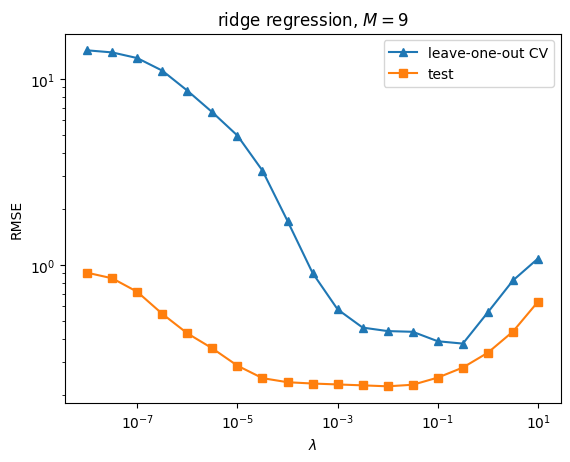

In [48]:
M = 9
features = lambda x: poly_features(x, M)
lams = np.logspace(-8, 1, 19)
cv_ridge = np.array([loocv_rmse(x_train, y_train, features, lambda Phi, y: fit_ridge(Phi, y, lam)) for lam in lams])
test_ridge = np.array([rmse(y_test, model(features, fit_ridge(features(x_train), y_train, lam))(x_test)) for lam in lams])
lam_best = lams[np.argmin(cv_ridge)]
print(f'lambda chosen by cross-validation: {lam_best:.1e}')

plt.figure()
plt.loglog(lams, cv_ridge, '^-', label='leave-one-out CV')
plt.loglog(lams, test_ridge, 's-', label='test')
plt.xlabel('$\\lambda$'); plt.ylabel('RMSE'); plt.title(f'ridge regression, $M={M}$'); plt.legend();

Finally, the two models chosen by cross-validation are evaluated **once** on the test set.

In [49]:
theta_A = fit_ml(poly_features(x_train, M_best), y_train)
theta_B = fit_ridge(poly_features(x_train, 9), y_train, lam_best)
print(f'A: degree {M_best}, maximum likelihood:   test RMSE = {rmse(y_test, poly_features(x_test, M_best) @ theta_A):.3f}')
print(f'B: degree 9, ridge with lambda = {lam_best:.0e}: test RMSE = {rmse(y_test, poly_features(x_test, 9) @ theta_B):.3f}')
print(f'noise level sigma = {sigma}')

A: degree 3, maximum likelihood:   test RMSE = 0.211
B: degree 9, ridge with lambda = 3e-01: test RMSE = 0.281
noise level sigma = 0.2


**Q9.** Which $\lambda$ does cross-validation choose? Describe what happens for very small and for very large $\lambda$.

**Q10.** Ridge regression is MAP estimation with the prior $\boldsymbol\theta\sim\mathcal N(\boldsymbol 0,b^2\boldsymbol I)$,
with $\lambda=\sigma^2/b^2$ (Lecture 4). With $\sigma=0.2$, which prior standard deviation $b$ corresponds to the chosen
$\lambda$? Why does a prior that prefers small parameters help here?

**Q11.** Why does $\lambda>0$ also cure the numerical problems of Q5? (Hint: the eigenvalues of
$\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I$.)

**Q9.** Cross-validation chooses $\lambda \approx 0.3$.
* **Very small $\lambda$:** the penalty does almost nothing, so ridge behaves like ordinary maximum likelihood. The degree-9 polynomial overfits and wiggles wildly between the points, and both the CV error and the test error are large.
* **Very large $\lambda$:** the penalty dominates and pushes all parameters towards zero. The curve becomes too flat to follow the data (underfitting), so the errors rise again.
* The best $\lambda$ lies in between: the curve is smooth but still follows the shape of the data.

The ridge model, test RMSE $0.281$, is slightly worse than the degree-3 model, test RMSE $0.211$, but much better than the unregularised degree-9 model. The test curve is lowest at a somewhat smaller $\lambda$ than the one CV chose, which is expected because CV only has 10 points to work with.

**Q10.** From $\lambda = \sigma^2/b^2$ we get $b = \sigma/\sqrt{\lambda} = 0.2/\sqrt{0.3} \approx 0.36$.
The prior says that before seeing any data, we expect the parameters to be small, roughly within $\pm 0.4$ or so. This helps because an overfitting polynomial needs very large parameters that cancel each other out to make its wild wiggles. The prior makes such solutions unlikely, so the fit stays smooth. Parameters that the data really need (like the cubic's coefficients) can still become larger, because the data pull them there.

**Q11.** The eigenvalues of $\boldsymbol\Phi^\top\boldsymbol\Phi$ are all $\ge 0$, and for large $M$ the smallest one is very close to $0$ (or exactly $0$ when there are too few points). That is what makes the system nearly singular and the condition number huge. Adding $\lambda\boldsymbol I$ adds $\lambda$ to every eigenvalue, so the smallest eigenvalue is now at least $\lambda$ and can never be close to zero. The matrix is therefore always invertible, and the condition number becomes much smaller. This is also why LOOCV works for $M = 9$ with only 9 points per fit.

## 7. The noise variance

The maximum likelihood estimate of the noise variance is the mean squared residual on the training data (Lecture 3),
$$
\sigma^2_{\mathrm{ML}}=\frac1N\sum_{n=1}^N\bigl(y_n-\boldsymbol\phi(x_n)^\top\boldsymbol\theta_{\mathrm{ML}}\bigr)^2 ,
$$
and dividing by $N-K$ instead of $N$ gives an unbiased estimate. Compute both for the degree chosen by cross-validation.

In [50]:
Phi = poly_features(x_train, M_best)
theta = fit_ml(Phi, y_train)
r = y_train - Phi @ theta
K = M_best + 1
s2_ml = np.sum(r**2) / N
s2_unbiased = np.sum(r**2) / (N - K)  
print(f'sigma^2_ML = {s2_ml:.4f},  unbiased estimate = {s2_unbiased:.4f},  true sigma^2 = {sigma**2:.4f}')

sigma^2_ML = 0.0231,  unbiased estimate = 0.0385,  true sigma^2 = 0.0400


With only $N=10$ training points the residuals say little about the shape of the noise distribution. The test set is
large, so we use its residuals to check the Gaussian noise model: the histogram should look like the density of
$\mathcal N(0,\hat\sigma^2)$.

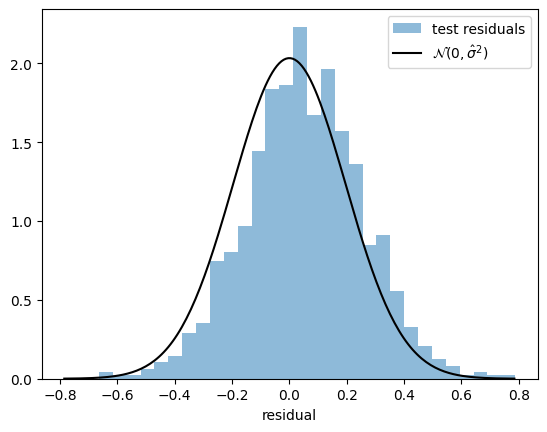

In [51]:
r_test = (y_test - poly_features(x_test, M_best) @ theta).ravel()
s = np.sqrt(s2_unbiased)
t = np.linspace(-4*s, 4*s, 200)
plt.figure()
plt.hist(r_test, bins=30, density=True, alpha=0.5, label='test residuals')
plt.plot(t, np.exp(-t**2/(2*s**2))/np.sqrt(2*np.pi*s**2), 'k', label='$\\mathcal{N}(0,\\hat\\sigma^2)$')
plt.xlabel('residual'); plt.legend();

**Q12.** Which of the two estimates is closer to the true $\sigma^2=0.04$? Why is $\sigma^2_{\mathrm{ML}}$ too small on
average? (Hint: it is a training error, Lecture 2.) Does the histogram support the Gaussian noise model?

The unbiased estimate ($0.0385$) is much closer to the true $\sigma^2 = 0.04$ than the ML estimate ($0.0231$).

$\sigma^2_{\mathrm{ML}}$ is too small on average because it is a training error. The curve was fitted to these same 10 points, so it has been pulled towards them and has partly fitted the noise too. The residuals are therefore smaller than the real noise. With $K = 4$ parameters and only $N = 10$ points the effect is large, the fit "uses up" 4 of the 10 points. Dividing by $N - K = 6$ instead of $N = 10$ corrects for this.

The histogram supports the Gaussian noise model where it is bell-shaped, roughly symmetric, and has about the same width as $\mathcal N(0, \hat\sigma^2)$. It is slightly shifted to the right of $0$ and a little wider than the curve. This is because the test residuals contain not only the noise but also the small error of the fitted curve itself. That doesn't contradict the Gaussian assumption.

## Optional extras
* Try other features, for example a Fourier basis $\phi_k(x)=\cos(k\pi x)$ and $\sin(k\pi x)$.
* Repeat the experiment with another seed, or with more training points ($N=30$). What changes?
* Find out how `sklearn.linear_model.LinearRegression` and `Ridge` do the same computations.